# Hafta 6 · Yapay Sinir Ağları

**Yapay Zekâya Giriş — Laboratuvar Defteri**  
Dr. Seda Bayat Toksöz · Iğdır Üniversitesi · 2026–2027 Güz

Bu defterde perceptron öğrenme kuralını, NumPy ile ileri yayılımı ve scikit-learn ile çok katmanlı bir ağı (MLP) çalıştıracaksınız. Çıktıları notlardaki çözümlü örneklerle karşılaştırın.

Hücreleri yukarıdan aşağıya sırayla çalıştırın (**Shift + Enter**). Parametreleri değiştirip sonucun nasıl değiştiğini gözlemleyin.

In [1]:
# Grafik ayarları (ders notlarıyla aynı renk paleti)
import matplotlib.pyplot as plt
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#0072B2", "#D55E00", "#009E73", "#E69F00", "#56B4E9", "#CC79A7"]),
})

## 1. Perceptron öğrenme kuralı (Çözümlü Örnek 6.2)
AND kapısı; başlangıç ağırlıkları w = [0.3, −0.1], b = 0, öğrenme oranı η = 0.5.

In [2]:
import numpy as np

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([0, 0, 0, 1])                   # AND kapısı
w, b, eta = np.array([0.3, -0.1]), 0.0, 0.5  # başlangıç

for epok in range(1, 5):
    hata = 0
    for xi, yi in zip(X, y):
        y_hat = 1 if w @ xi + b >= 0 else 0  # basamak
        e = yi - y_hat                       # hata
        w, b = w + eta*e*xi, b + eta*e       # öğrenme kuralı
        hata += int(e != 0)
    print(f"epok {epok}: w={w.round(2)}, b={b:.1f}, hata={hata}")

epok 1: w=[0.8 0.4], b=0.0, hata=2
epok 2: w=[0.8 0.9], b=-0.5, hata=3
epok 3: w=[0.8 0.4], b=-1.0, hata=1
epok 4: w=[0.8 0.4], b=-1.0, hata=0


## 2. NumPy ile ileri yayılım (Çözümlü Örnek 6.4)

In [3]:
def relu(z):    return np.maximum(0, z)
def sigmoid(z): return 1 / (1 + np.exp(-z))

# Çözümlü Örnek 6.4'teki ağ
x  = np.array([1.0, 2.0])
W1 = np.array([[-0.5, 0.1],
               [ 0.2, 0.8]]);  b1 = np.array([0.1, -0.2])
W2 = np.array([[0.7, 0.5]]);   b2 = np.array([-0.3])

h     = relu(W1 @ x + b1)       # gizli katman: [0. 1.6]
y_hat = sigmoid(W2 @ h + b2)    # çıkış: ≈ 0.6225
print(h, y_hat)

[0.  1.6] [0.62245933]


### Yığın hâlinde ileri yayılım (Çözümlü Örnek 6.6)
Örnekler satırlara yerleştirilir; tüm yığın tek bir matris çarpımıyla hesaplanır: Z = A Wᵀ + b.

In [4]:
X = np.array([[1.0, 2.0],
              [0.0, 1.0]])           # her satır bir örnek
A1 = relu(X @ W1.T + b1)             # bias her satıra eklenir
y_hat = sigmoid(A1 @ W2.T + b2)
print(A1)
print(y_hat.ravel().round(3))        # [0.622 0.535]

[[0.  1.6]
 [0.2 0.6]]
[0.622 0.535]


### Parametre sayısı (Çözümlü Örnek 6.5)
Tam bağlı katman: n_girdi × n_çıktı + n_çıktı.

In [5]:
katmanlar = [784, 128, 64, 10]
toplam = 0
for n_g, n_c in zip(katmanlar[:-1], katmanlar[1:]):
    p = n_g * n_c + n_c
    toplam += p
    print(f"{n_g:>4} → {n_c:<4}: {p:>7}")
print("toplam:", toplam)

 784 → 128 :  100480
 128 → 64  :    8256
  64 → 10  :     650
toplam: 109386


## 3. scikit-learn ile çok katmanlı perceptron
İç içe iki halka biçimindeki veri tek bir doğruyla ayrılamaz; iki gizli katmanlı bir MLP eğitelim.

In [6]:
from sklearn.datasets import make_circles
from sklearn.neural_network import MLPClassifier

# İç içe halkalar verisinde iki gizli katmanlı MLP
X, y = make_circles(n_samples=500, noise=0.1, factor=0.45,
                    random_state=1)
ag = MLPClassifier(hidden_layer_sizes=(16, 16), activation="relu",
                   max_iter=2000, random_state=0).fit(X, y)
print("doğruluk:", ag.score(X, y))
print("parametre:", sum(W.size for W in ag.coefs_) +
                    sum(b.size for b in ag.intercepts_))

doğruluk: 0.996
parametre: 337


### Öğrenilen karar sınırı

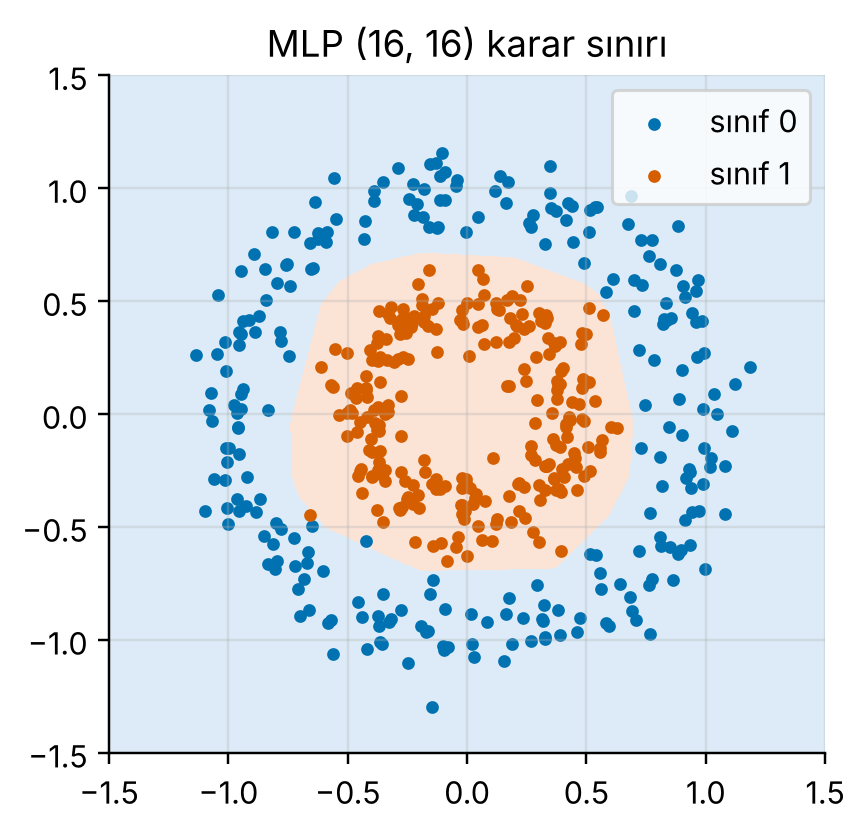

In [7]:
import matplotlib.pyplot as plt

g = np.linspace(-1.5, 1.5, 300)
xx, yy = np.meshgrid(g, g)
izgara = np.c_[xx.ravel(), yy.ravel()]
p = ag.predict_proba(izgara)[:, 1].reshape(xx.shape)

plt.figure(figsize=(4.2, 4))
plt.contourf(xx, yy, p, levels=[0, 0.5, 1],
             colors=["#DCEBF7", "#FBE3D6"])
plt.scatter(*X[y == 0].T, s=10, c="#0072B2", label="sınıf 0")
plt.scatter(*X[y == 1].T, s=10, c="#D55E00", label="sınıf 1")
plt.legend(loc="upper right")
plt.title("MLP (16, 16) karar sınırı")
plt.show()

### Alıştırma (Değerlendirme Sorusu 8)
Çözümlü Örnek 6.4'teki ağın x = [2, 1] girdisi için çıktısını önce elle hesaplayın, sonra hücreyi çalıştırın.

In [ ]:
x2 = np.array([2.0, 1.0])
h2 = relu(W1 @ x2 + b1)
print("h =", h2, "  y_hat =", sigmoid(W2 @ h2 + b2).round(3))